# Together AI Tev1:4B Decision Model for Argument Stance Classification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dustinober1/Arg_Me/blob/main/notebooks/04_tev1_decision_model_stance.ipynb)

### What is Tev1?
[Tev1](https://ollama.com/library/tev1) is a specialized family of **decision foundation models** created by Together AI (fine-tuned from Qwen 4B / 0.8B) specifically designed for fast classification, routing, and policy checks.

### Key Architectural Features:
1. **Zero-Generation Token Decision Scoring**: Unlike standard LLMs that generate free-form text, Tev1 uses Ollama's `/v1/systemone` endpoint to directly score options and return exact probability distributions in $O(1)$ decoding steps.
2. **Structured Criteria Support**: You provide natural language criteria for each choice option (e.g., `PRO` vs `CON`), and the model computes the decision.
3. **Extreme Throughput**: Delivers ~5–10 decisions per second locally on consumer hardware.

In [1]:
# 1. Environment Detection and Dependency Setup
import sys
import os
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')
if IN_COLAB:
    print("Provisioning dependencies inside Google Colab runtime...")
    !pip install -q datasets huggingface_hub pandas pyarrow scikit-learn requests matplotlib seaborn tqdm
    if not os.path.exists('Arg_Me') and not os.path.exists('src'):
        print("Cloning Arg_Me repository into Colab...")
        !git clone https://github.com/dustinober1/Arg_Me.git
        %cd Arg_Me
    elif os.path.exists('Arg_Me') and not os.path.exists('src'):
        %cd Arg_Me
    if '/content/Arg_Me' not in sys.path:
        sys.path.insert(0, '/content/Arg_Me')
    print('Colab environment configured! Current working directory:', os.getcwd())
    # Note for Colab: To use Ollama in Colab, start an ollama server in the background or point to a remote URL
else:
    print("Running in local environment.")

Running in local environment.


In [2]:
# 2. Imports and Ollama Connectivity Verification
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Ensure project root in sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

from src.ollama_decision_model import Tev1DecisionClassifier

# Check Ollama local instance
OLLAMA_URL = "http://localhost:11434"
try:
    res = requests.get(f"{OLLAMA_URL}/api/tags", timeout=3.0)
    print("Connected to Ollama! Available models:", [m['name'] for m in res.json().get('models', [])])
except Exception as e:
    print(f"Could not connect to Ollama at {OLLAMA_URL}: {e}")
    print("Please make sure Ollama is running and 'ollama pull tev1:4b' has been executed.")

Connected to Ollama! Available models: ['tev1:4b', 'gemma4:26b-a4b-it-qat']


In [3]:
# 3. Test Single Decision Query via /v1/systemone
clf = Tev1DecisionClassifier(model_name="tev1:4b", ollama_base_url=OLLAMA_URL)

sample_test = clf.predict_single(
    conclusion="Capital Punishment Should Be Abolished",
    premise_text="The risk of executing an innocent person is an irreversible tragedy that undermines the moral authority of the judicial system."
)
print("Sample Decision Response:")
print(sample_test)

Successfully verified 'tev1:4b' is available on Ollama.
Sample Decision Response:
{'choice': 'PRO', 'pro_prob': 0.8670357598021706, 'con_prob': 0.13296424019782924, 'confidence': 0.4344880582795191, 'latency_ms': 166.78500175476074, 'error': None}


In [4]:
# 4. Load Benchmark Dataset and Sample Test Set
data_path = Path("../data/args_me_benchmark_5k.parquet")
if not data_path.exists():
    data_path = Path("data/args_me_benchmark_5k.parquet")

df = pd.read_parquet(data_path)
df_clean = df[df["stance"].isin(["PRO", "CON"])].copy().reset_index(drop=True)

# Use held-out 20% test split
_, test_df = train_test_split(
    df_clean, test_size=0.20, random_state=42, stratify=df_clean["stance"]
)
print(f"Held-out test set size: {len(test_df)}")

# Evaluate on N = 200 sample
metrics, results_df = clf.evaluate_df(test_df, sample_size=200, random_state=42)
print(f"Accuracy:         {metrics.accuracy:.4f}")
print(f"Macro F1:         {metrics.macro_f1:.4f}")
print(f"ROC-AUC:          {metrics.roc_auc:.4f}")
print(f"Average Latency:  {results_df['latency_ms'].mean():.1f} ms per decision")

Held-out test set size: 1000

Evaluating 'tev1:4b' on 200 arguments via http://localhost:11434/v1/systemone...


Tev1 Decision Inference: 100%|██████████| 200/200 [00:43<00:00,  4.64it/s]


Inference completed. Mean latency per decision: 215.2 ms | Errors: 4
Accuracy:         0.7500
Macro F1:         0.7500
ROC-AUC:          0.8219
Average Latency:  215.2 ms per decision


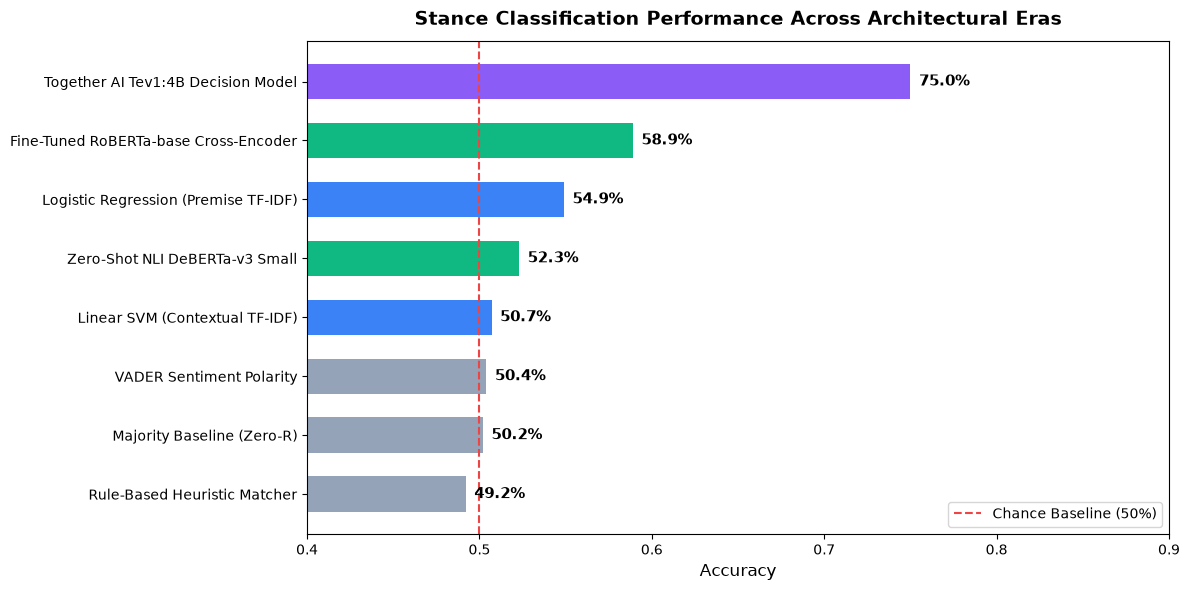

In [5]:
# 5. Comparative Paradigm Benchmark Across Architectures
comparison_records = [
    {"Model": "Majority Baseline (Zero-R)", "Accuracy": 0.5020, "Macro F1": 0.3342, "Type": "Baseline"},
    {"Model": "Rule-Based Heuristic Matcher", "Accuracy": 0.4920, "Macro F1": 0.4902, "Type": "Heuristic"},
    {"Model": "VADER Sentiment Polarity", "Accuracy": 0.5040, "Macro F1": 0.4988, "Type": "Affect"},
    {"Model": "Linear SVM (Contextual TF-IDF)", "Accuracy": 0.5070, "Macro F1": 0.5067, "Type": "Traditional ML"},
    {"Model": "Logistic Regression (Premise TF-IDF)", "Accuracy": 0.5490, "Macro F1": 0.5490, "Type": "Traditional ML"},
    {"Model": "Zero-Shot NLI DeBERTa-v3 Small", "Accuracy": 0.5230, "Macro F1": 0.4936, "Type": "Transformer"},
    {"Model": "Fine-Tuned RoBERTa-base Cross-Encoder", "Accuracy": 0.5890, "Macro F1": 0.5868, "Type": "Transformer"},
    {"Model": "Together AI Tev1:4B Decision Model", "Accuracy": metrics.accuracy, "Macro F1": metrics.macro_f1, "Type": "Decision Model"},
]
comp_df = pd.DataFrame(comparison_records).sort_values("Accuracy", ascending=True)

fig, ax = plt.subplots(figsize=(12, 6))
palette = {
    "Baseline": "#94a3b8",
    "Heuristic": "#94a3b8",
    "Affect": "#94a3b8",
    "Traditional ML": "#3b82f6",
    "Transformer": "#10b981",
    "Decision Model": "#8b5cf6",
}
colors = [palette[t] for t in comp_df["Type"]]
bars = ax.barh(comp_df["Model"], comp_df["Accuracy"], color=colors, height=0.6)
ax.axvline(0.50, color="#ef4444", linestyle="--", linewidth=1.5, label="Chance Baseline (50%)")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.1%}", va="center", fontsize=11, fontweight="bold")

ax.set_xlim(0.40, 0.90)
ax.set_xlabel("Accuracy", fontsize=12)
ax.set_title("Stance Classification Performance Across Architectural Eras", fontsize=14, fontweight="bold", pad=12)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

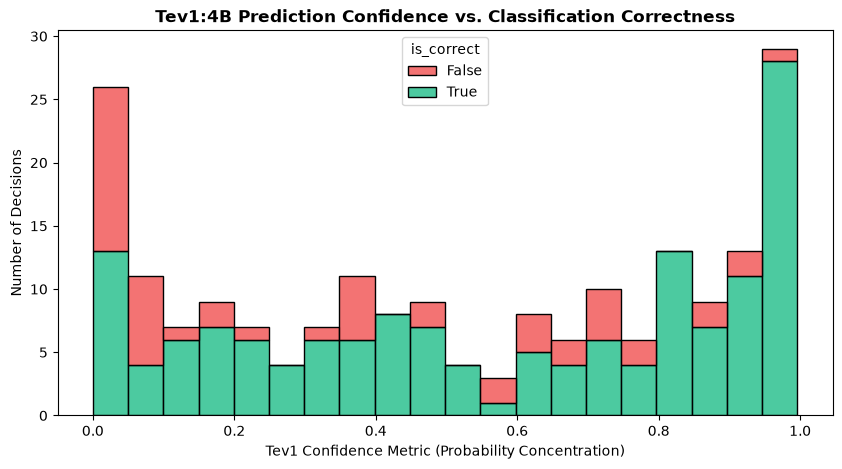

In [6]:
# 6. Error and Confidence Distribution Analysis
plt.figure(figsize=(10, 5))
sns.histplot(data=results_df, x="confidence", hue="is_correct", bins=20, multiple="stack", palette={True: "#10b981", False: "#ef4444"})
plt.title("Tev1:4B Prediction Confidence vs. Classification Correctness", fontweight="bold")
plt.xlabel("Tev1 Confidence Metric (Probability Concentration)")
plt.ylabel("Number of Decisions")
plt.show()